# 04 — Feature Engineering, Split Data, dan Rezim Pasar

Dua jalur pembentukan fitur yang dipakai notebook eksperimen (05, 06, 07), plus penjelasan **mengapa split 70/10/20 kronologis dipertahankan** dan seperti apa tiga periodenya.

1. **Fitur tabular** (10 model ML): `lag_0` (return hari-i, diketahui saat prediksi) + 8 lag return + 6 statistik rolling (jendela berakhir di hari-i) + (opsional) 7 fitur makro **stasioner** → 15 fitur (univariat) / 22 fitur (multivariat).
2. **Sliding window** (11 model DL): jendela `SEQ_LEN = 10` hari multi-channel, z-score yang di-fit **hanya** pada data latih.

Fungsi yang dipakai (`build_lgb_features`, `multihorizon_split`) diimpor dari `src/pipeline.py` — modul yang sama persis dipakai notebook 05–07.

In [1]:
import sys, os, json, time, warnings
sys.path.insert(0, os.path.join('..'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import (OUT, HORIZONS, SETUPS, ML_MODELS, DL_MODELS, ALL_MODELS, LANG, PROTOCOL, ML_REV, QUICK)
from src import analysis as A, plots as P, stats as S
from src.runners import load_data, data_fingerprint

P.set_lang(LANG)
RES = os.path.join(OUT, 'results')
RUNS = os.path.join(RES, 'runs')
FIGS = os.path.join(OUT, 'figures')
for _d in (RES, RUNS, FIGS):
    os.makedirs(_d, exist_ok=True)

df, p, exo = load_data('..')
DATA_HASH = data_fingerprint(df)
print(f'Data: {len(p)} hari kerja, {p.index[0].date()} s.d. {p.index[-1].date()} | sidik jari {DATA_HASH}'
      + (' | MODE QUICK (hasil hanya uji kelancaran)' if QUICK else ''))


def simpan(fig, nama):
    """Simpan figur (PNG + PDF) ke outputs/figures lalu tampilkan."""
    P.save_fig(fig, nama, FIGS)
    plt.show()
    plt.close(fig)

from src.pipeline import (build_lgb_features, multihorizon_split, EXO_COLS, EXO_CLIP, LAGS, WINDOWS)
from src.config import SEQ_LEN

print('LAGS   :', LAGS)
print('WINDOWS:', WINDOWS)
print('EXO_COLS:', EXO_COLS)

Data: 4325 hari kerja, 2010-01-05 s.d. 2026-08-03 | sidik jari 7aea8db80d44
LAGS   : (1, 2, 3, 5, 7, 14, 21, 30)
WINDOWS: (7, 14, 30)
EXO_COLS: ['dxy_ret', 'sp500_ret', 'usd_idr_ret', 'ihsg_ret', 'us10yr_diff', 'ffr_diff', 'bi_rate_diff']


## 1. Fitur Tabular (ML)

`build_lgb_features` menghasilkan 15 fitur pada setting **univariat** dan 22 fitur pada setting **multivariat** (+ 7 fitur makro stasioner yang sudah di-lag 1 hari sejak tahap penggabungan data).

In [2]:
F_univariat = build_lgb_features(p)
F_multivariat = build_lgb_features(p, exo)
print(f'Univariat  : {F_univariat.shape[1]} fitur, {F_univariat.shape[0]} baris (setelah dropna)')
print(f'Multivariat: {F_multivariat.shape[1]} fitur, {F_multivariat.shape[0]} baris (setelah dropna)')
print()
print('Kolom univariat            :', F_univariat.columns.tolist())
print('Kolom tambahan multivariat :', [c for c in F_multivariat.columns if c not in F_univariat.columns])
F_multivariat.head()

Univariat  : 15 fitur, 4294 baris (setelah dropna)
Multivariat: 22 fitur, 4294 baris (setelah dropna)

Kolom univariat            : ['lag_0', 'lag_1', 'lag_2', 'lag_3', 'lag_5', 'lag_7', 'lag_14', 'lag_21', 'lag_30', 'roll_mean_7', 'roll_std_7', 'roll_mean_14', 'roll_std_14', 'roll_mean_30', 'roll_std_30']
Kolom tambahan multivariat : ['dxy_ret', 'sp500_ret', 'usd_idr_ret', 'ihsg_ret', 'us10yr_diff', 'ffr_diff', 'bi_rate_diff']


,lag_0,lag_1,lag_2,lag_3,lag_5,lag_7,lag_14,lag_21,lag_30,roll_mean_7,...,roll_std_14,roll_mean_30,roll_std_30,dxy_ret,sp500_ret,usd_idr_ret,ihsg_ret,us10yr_diff,ffr_diff,bi_rate_diff
tanggal,,,,,,,,,,,,,,,,,,,,,
2010-02-17,0.007444,0.002488,-0.002481,0.004988,0.002494,-0.002494,-0.002475,0.009852,0.000000,0.002135,...,0.004147,-0.000316,0.004775,-0.007749,0.017841,-0.005569,0.016174,-0.03,0.0,0.0
2010-02-18,-0.012315,0.007444,0.002488,-0.002481,-0.002488,0.002500,0.000000,0.000000,0.004878,0.000018,...,0.005390,-0.000889,0.005147,0.008496,0.004229,0.011523,0.008886,0.08,0.0,0.0
2010-02-19,0.000000,-0.012315,0.007444,0.002488,0.004988,0.002494,0.000000,-0.004878,-0.004854,-0.000338,...,0.005390,-0.000727,0.005094,0.000249,0.006563,0.010497,-0.008288,0.05,0.0,0.0
2010-02-22,0.017456,0.000000,-0.012315,0.007444,-0.002481,-0.002488,0.004963,-0.009804,0.007317,0.002511,...,0.007099,-0.000389,0.005916,0.002981,0.002184,-0.022095,-0.002213,-0.01,0.0,0.0
2010-02-23,-0.014706,0.017456,0.000000,-0.012315,0.002488,0.004988,0.002469,0.000000,-0.007264,-0.000302,...,0.008148,-0.000637,0.006354,-0.001613,-0.001046,-0.001131,0.003863,0.02,0.0,0.0


## 2. Pembagian Data 70/10/20 (Horizon-Aware, Kronologis)

`multihorizon_split` membagi **kronologis murni** (tanpa pengacakan): 70% latih / 10% validasi / 20% uji dari `n − h` posisi yang punya target. Batas split sedikit bergeser antar horizon (jumlah origin uji 859–864).

**Embargo.** Target posisi *i* adalah `p[i+h]`. Baris validasi yang target-nya (`i+h`) jatuh di periode uji **tidak** dipakai untuk early stopping/metrik validasi (dibuktikan oleh guard di notebook 05 dan 08).

In [3]:
rows = []
for h in [1, 5, 10, 20, 30]:
    tr_dates, va_dates, te_pos = multihorizon_split(p, h)
    n_emb = sum(1 for d in va_dates if p.index.get_loc(d) + h < te_pos[0])
    rows.append({'h': h, 'latih': len(tr_dates), 'validasi': len(va_dates), 'validasi_dipakai (embargo)': n_emb, 'uji': len(te_pos),
                 'latih_s.d.': tr_dates[-1].date(), 'validasi_s.d.': va_dates[-1].date(),
                 'uji_mulai': p.index[te_pos[0]].date(), 'uji_akhir_origin': p.index[te_pos[-1]].date(),
                 'target_terakhir': p.index[te_pos[-1] + h].date()})
tabel_split = pd.DataFrame(rows)
tabel_split.to_csv(os.path.join(RES, 'tabel_split.csv'), index=False)
tabel_split

,h,latih,validasi,validasi_dipakai (embargo),uji,latih_s.d.,validasi_s.d.,uji_mulai,uji_akhir_origin,target_terakhir
0,1,3028,432,431,864,2021-08-12,2023-04-10,2023-04-11,2026-07-31,2026-08-03
1,5,3024,432,427,864,2021-08-06,2023-04-04,2023-04-05,2026-07-27,2026-08-03
2,10,3021,431,421,863,2021-08-03,2023-03-29,2023-03-30,2026-07-20,2026-08-03
3,20,3014,430,410,861,2021-07-23,2023-03-17,2023-03-20,2026-07-06,2026-08-03
4,30,3007,429,399,859,2021-07-14,2023-03-07,2023-03-08,2026-06-22,2026-08-03


## 3. Tiga Periode Itu Tidak Sama: Rezim Pasar

Ini penjelasan atas pertanyaan *"apakah split 70/10/20 masuk akal untuk data emas seperti ini?"*. Gambar dan tabel di bawah menunjukkan bahwa:

- **latih** (≈2010–2021) memuat harga rendah (≈0,4–1,1 juta Rp/g), banyak hari basi;
- **validasi** (≈2021–2023) adalah periode **sideways dan tenang** (volatilitas harian paling rendah dari ketiganya);
- **uji** (≈2023–2026) adalah **reli panjang dan lebih bergejolak** (harga naik ≈3×).

Akibatnya: (i) *loss validasi bisa lebih rendah dari loss latih* — itu artefak rezim, bukan tanda kebocoran; (ii) tuning pada validasi (MOSSA, early stopping) kurang representatif untuk uji; (iii) satu blok uji menggambarkan satu rezim saja. Kebijakan di proyek ini lihat bagian 4.

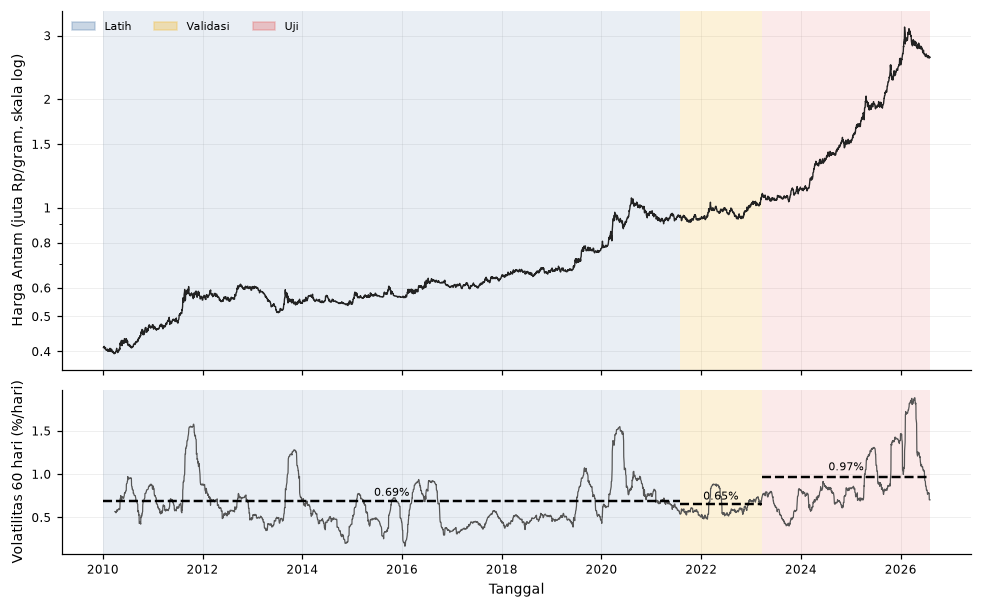

,periode,awal,akhir,n,harga_min_juta,harga_maks_juta,sd_harian_%,rata2_R20_%,sd_R20_%,porsi_R20_naik_%,porsi_return_nol_%
0,latih,2010-01-05,2021-07-23,3014,0.39,1.06,0.69,0.60,2.87,51.96,22.47
1,validasi,2021-07-26,2023-03-17,430,0.91,1.06,0.65,0.68,2.59,59.30,12.79
2,uji,2023-03-20,2026-07-06,861,1.04,3.17,0.97,2.18,4.38,66.32,7.20


In [4]:
tr_dates, va_dates, te_pos = multihorizon_split(p, 20)
te_dates = p.index[te_pos]
bounds = {'val_start': va_dates[0], 'test_start': te_dates[0]}
fig = P.fig_price_regimes(p, bounds)
simpan(fig, 'fig_harga_rezim')

r1 = p.pct_change()
R20 = p.shift(-20) / p - 1
tabel_rezim = []
for nama, idx in (('latih', tr_dates), ('validasi', va_dates), ('uji', te_dates)):
    rr = r1.reindex(idx).dropna()
    r20 = R20.reindex(idx).dropna()
    tabel_rezim.append({'periode': nama, 'awal': idx[0].date(), 'akhir': idx[-1].date(), 'n': len(idx),
                        'harga_min_juta': p.reindex(idx).min() / 1e6, 'harga_maks_juta': p.reindex(idx).max() / 1e6,
                        'sd_harian_%': rr.std() * 100, 'rata2_R20_%': r20.mean() * 100, 'sd_R20_%': r20.std() * 100,
                        'porsi_R20_naik_%': (r20 > 0).mean() * 100, 'porsi_return_nol_%': (rr == 0).mean() * 100})
tabel_rezim = pd.DataFrame(tabel_rezim).round(2)
tabel_rezim.to_csv(os.path.join(RES, 'rezim_periode_split.csv'), index=False)
tabel_rezim

## 4. Keputusan Split (dan Alasannya)

| Opsi | Penilaian |
|---|---|
| **70/10/20 kronologis dengan embargo** (utama) | Dipertahankan: sejajar dengan jurnal acuan (Bao et al.), seluruh 21 model dievaluasi pada baris uji yang identik, tanpa kebocoran. |
| K-fold / pengacakan | **Tidak valid** untuk deret waktu: target h-hari saling tumpang-tindih sehingga baris latih dan uji berbagi informasi. |
| **Walk-forward (expanding window, 6 fold × 260 hari)** | Dijalankan sebagai analisis ketahanan di **notebook 16**: menguji apakah kesimpulan bergantung pada satu rezim uji. |
| Sub-periode & rezim volatilitas | Di **notebook 12**: hasil dipecah per blok waktu uji dan tingkat volatilitas. |

Split ulang (mis. 60/10/30 atau memajukan batas uji) **tidak** dipilih: memilih batas karena hasilnya "lebih bagus" adalah *data snooping*. Cara yang benar adalah melaporkan hasil utama apa adanya lalu menunjukkan ketahanannya (notebook 12 dan 16).

## 5. Sliding Window (Deep Learning)

Jendela `SEQ_LEN = 10` hari dipakai sebagai input multi-channel (channel = return emas + 7 fitur makro stasioner pada setting multivariat). **Z-score** di-fit **hanya** pada rentang latih lalu diterapkan ke seluruh deret. Kanal eksogen di-clip ke ±`EXO_CLIP` sesudah z-score (pengaman terhadap lonjakan ekstrem seperti kenaikan FFR 2022 yang belum pernah terjadi di data latih).

In [5]:
from sklearn.preprocessing import StandardScaler

H_DEMO = 20
r1f = p.pct_change().fillna(0)
tr_dates, va_dates, te_pos = multihorizon_split(p, h=H_DEMO)
tr_pos = list(range(len(tr_dates)))

sc_emas = StandardScaler().fit(r1f.iloc[tr_pos].values.reshape(-1, 1))
z_emas = sc_emas.transform(r1f.values.reshape(-1, 1)).flatten()
Z_exo = np.column_stack([
    np.clip(StandardScaler().fit(exo[c].iloc[tr_pos].values.reshape(-1, 1))
            .transform(exo[c].values.reshape(-1, 1)).flatten(), -EXO_CLIP, EXO_CLIP) for c in EXO_COLS])

i = 100 + SEQ_LEN
window_uni = z_emas[i - SEQ_LEN + 1:i + 1]
window_multi = np.column_stack([z_emas, Z_exo])[i - SEQ_LEN + 1:i + 1]
print(f'Window univariat  : shape {window_uni.shape}   (SEQ_LEN={SEQ_LEN} hari x 1 kanal)')
print(f'Window multivariat: shape {window_multi.shape} (SEQ_LEN x {1 + len(EXO_COLS)} kanal)')
print('\nContoh window univariat (z-score):')
print(window_uni.round(3))

Window univariat  : shape (10,)   (SEQ_LEN=10 hari x 1 kanal)
Window multivariat: shape (10, 8) (SEQ_LEN x 8 kanal)

Contoh window univariat (z-score):
[ 0.976  0.632 -0.043 -0.379 -1.054  0.635 -0.718 -1.4    2.011  2.319]


## 6. Kerangka Penelitian (Diagram)

Alur dari data mentah sampai uji statistik, digambar dari konfigurasi proyek ini (jumlah model, horizon, dan rentang data dibaca dari `src/config.py` dan data), sebagai padanan Fig. 1 jurnal acuan. Gambar ini orisinal (digambar dari kode), bukan salinan gambar jurnal.

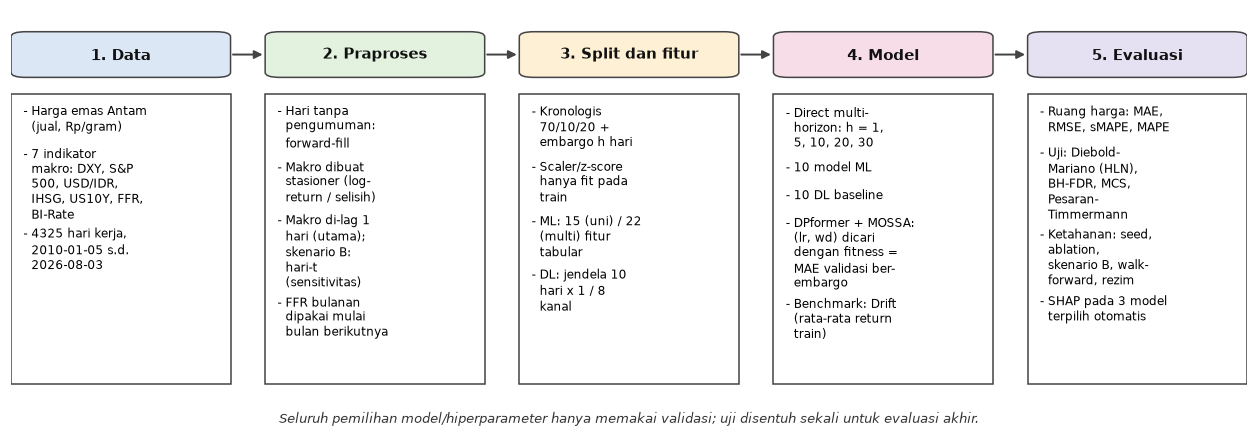

In [6]:
info = {'n': len(p), 'start': str(p.index[0].date()), 'end': str(p.index[-1].date()),
        'horizons': HORIZONS, 'n_ml': len(ML_MODELS), 'n_dl': len(DL_MODELS) - 1}   # DL_MODELS memuat DPformer; baseline = 10
fig = P.fig_framework(info)
simpan(fig, 'fig_kerangka_penelitian')